# Non-Circular Alternatives for Calling Dysbiotic Samples (Recalled Species)

Follow-up to `dysbiosis_threshold_sweep_de.ipynb`. Rare-excess and core-loss definitions are compared there. This notebook tries other ways of picking out "dysbiotic" plants, all built from the **microbiome or microbial load only**, so none of them uses the defense genes or the defense score. That keeps them non-circular: the defense score is only used afterwards to check whether the groups end up being high-defense plants.

**Candidate measures** (one value per plant):

| Measure | Dysbiotic end | Idea |
|---|---|---|
| Community atypicality | high | Bray-Curtis distance from the mean community of the *other* plants at the same timepoint |
| Shannon diversity | low | loss of diversity |
| Dominance | high | % of reads in the single most abundant species (bloom) |
| *Pseudomonas* abundance | high | all *Pseudomonas* species summed, chosen a priori as the main phyllosphere pathogen genus |
| Bacterial load (`ham16s`) | high | bacterial 16S reads relative to host reads |
| Fungal load (`hamits`) | high | fungal ITS reads relative to host reads |
| Rare-species abundance | high | the current rule (rare < 10% prevalence), ranked within timepoint |
| Core-species abundance | low | core loss (core > 80% prevalence), ranked within timepoint |

**Within-timepoint ranking:** each measure is z-scored within its timepoint before picking the top `group_sizes` (40, 80) plants. Most measures drift over the season, and DESeq2 has timepoint in the design, so a group concentrated in a few timepoints has little power. Ranking within timepoint spreads the dysbiotic plants across the season.

**One defense-informed option, flagged separately:** a cross-validated model predicting the defense score from the microbiome. Each plant's prediction comes from a model trained on *other timepoints*, so its own defense score is never used. But the definition is still tuned towards defense, so it isn't independent in the way the other measures are.

DESeq2 (`~timepoint + group`) and gene filters are the same as in the sweep notebook. Runs are cached in `Generated_data/dysbiosis_alternative_groupings_recalled_species/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
from pathlib import Path
import statsmodels.formula.api as smf
from scipy.stats import zscore
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds

from scipy.spatial.distance import braycurtis
from skbio.diversity.alpha import shannon
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, cross_val_predict

###Define Thresholds
group_sizes = [40, 80]
rare_prevalence_threshold = 0.1
core_prevalence_threshold = 0.8
min_prevalence_for_prediction = 0.1  # species used in the defense-prediction model
log_pseudocount = 0.05
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21
n_cpus = 6
results_dir = Path(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/dysbiosis_alternative_groupings_recalled_species"
)

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

# Same gene filters as the dysbiosis DE notebook
cleaned_raw_transcriptome = trimmed_raw_transcriptome.loc[
    :, trimmed_raw_transcriptome.sum() > expressed_gene_reads_threshold
]
cleaned_raw_transcriptome = cleaned_raw_transcriptome.loc[
    :, (cleaned_raw_transcriptome > 1).sum() > number_of_samples_expressed_in_threshold
]
print("Genes kept for DESeq2:", cleaned_raw_transcriptome.shape[1])

# Defense score: only used to describe the groups, never to define them
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
defense_genes = set(defense_gene_list["gene"])
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_genes)
]
trimmed_metadata["Defense Score"] = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)

# Old species-level DE genes (59, plates 1-5), for overlap
old_de_genes = set(
    pd.read_csv(
        "/Users/michael/Data/Luke_terrace_experiment/General_data/Junk_data/large_deseq_gene_list_all_plates.csv",
        header=None,
    )[0]
)

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


Genes kept for DESeq2: 18032


## Species abundance and load

In [3]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0) are
### dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]

# Sample x species abundance as % of each sample's reads (absent species = 0)
species_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Species", aggfunc="sum", fill_value=0
)
species_abundance_matrix = species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
seasonal_prevalence = (species_abundance_matrix.loc[seasonal_samples] > 0).mean()

# Transcriptome samples, all with a microbiome profile
de_samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(species_abundance_matrix.index)]
print("Transcriptomes with a microbiome profile:", len(de_samples), "of", len(trimmed_metadata))
sample_species = species_abundance_matrix.loc[trimmed_metadata.loc[de_samples, "sampID"]].set_index(de_samples)

load_table = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_ham_16S_ITS.csv", index_col=0
)

Transcriptomes with a microbiome profile: 426 of 426


## Candidate measures

In [4]:
timepoint = trimmed_metadata.loc[de_samples, "timepoint"]
sample_ids = trimmed_metadata.loc[de_samples, "sampID"]

# Atypicality: Bray-Curtis distance to the mean community of the other plants at the timepoint
atypicality = pd.Series(index=de_samples, dtype=float)
for tp, members in timepoint.groupby(timepoint).groups.items():
    for sample in members:
        others = sample_species.loc[[m for m in members if m != sample]].mean()
        atypicality[sample] = braycurtis(sample_species.loc[sample], others)

species_genus = plant_microbiome.drop_duplicates("Species").set_index("Species")["Genus"]
pseudomonas_species = species_genus.index[species_genus.str.startswith("g__Pseudomonas")]
rare_species = seasonal_prevalence.index[seasonal_prevalence < rare_prevalence_threshold]
core_species = seasonal_prevalence.index[seasonal_prevalence > core_prevalence_threshold]

measures = pd.DataFrame(
    {
        "atypicality": atypicality,
        "shannon": sample_species.apply(lambda row: shannon(row.to_numpy()), axis=1),
        "dominance": sample_species.max(axis=1),
        "pseudomonas": np.log10(sample_species[pseudomonas_species].sum(axis=1) + log_pseudocount),
        "bacterial load": np.log10(sample_ids.map(load_table["ham16s"])),
        "fungal load": np.log10(sample_ids.map(load_table["hamits"])),
        "rare abundance": sample_species[rare_species].sum(axis=1),
        "core abundance": sample_species[core_species].sum(axis=1),
    },
    index=de_samples,
)
# Which end of each measure is "dysbiotic"
dysbiotic_direction = {
    "atypicality": 1, "shannon": -1, "dominance": 1, "pseudomonas": 1,
    "bacterial load": 1, "fungal load": 1, "rare abundance": 1, "core abundance": -1,
}
print(f"Pseudomonas species: {len(pseudomonas_species)}; rare: {len(rare_species)}; core: {len(core_species)}")
print("Missing values:", measures.isna().sum()[measures.isna().sum() > 0].to_dict())
measures.describe().round(3)

Pseudomonas species: 15; rare: 434; core: 40
Missing values: {'bacterial load': 3, 'fungal load': 3}


,atypicality,shannon,dominance,pseudomonas,bacterial load,fungal load,rare abundance,core abundance
count,426.000,426.000,426.000,426.000,423.000,423.000,426.000,426.000
mean,0.415,3.285,21.650,0.561,-0.912,0.118,1.428,77.178
std,0.089,0.373,8.835,0.426,0.251,0.256,1.967,10.364
min,0.230,1.267,5.057,-0.466,-1.503,-0.803,0.000,26.800
25%,0.345,3.084,15.374,0.243,-1.095,-0.045,0.377,72.853
50%,0.404,3.298,19.987,0.550,-0.976,0.141,0.772,79.592
75%,0.469,3.500,26.047,0.872,-0.768,0.301,1.675,84.555
max,0.761,4.409,77.297,1.899,0.041,0.689,21.240,94.536


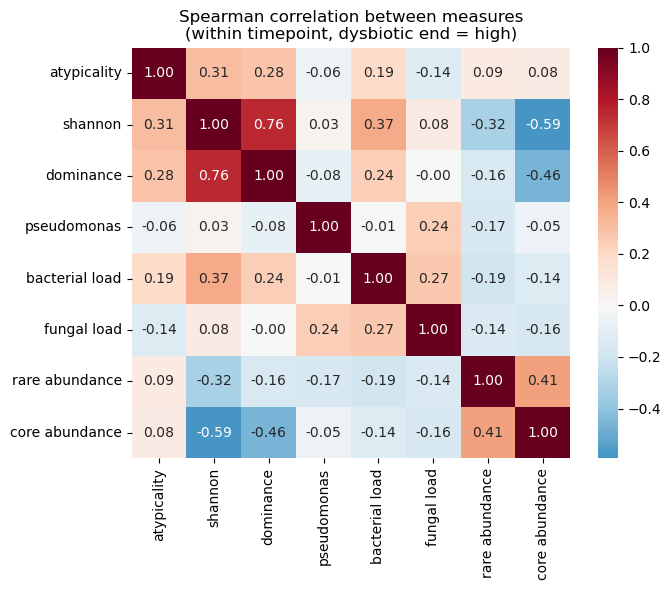

In [5]:
# Within-timepoint z-scores, signed so that higher = more dysbiotic
within_timepoint_z = measures.groupby(timepoint).transform(lambda x: (x - x.mean()) / x.std())
for measure, direction in dysbiotic_direction.items():
    within_timepoint_z[measure] *= direction

fig, ax = plt.subplots(figsize=(7, 6))
fig.patch.set_facecolor("white")
sns.heatmap(
    within_timepoint_z.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax
)
ax.set_title("Spearman correlation between measures\n(within timepoint, dysbiotic end = high)", fontsize=12)
plt.tight_layout()

### How each measure relates to the defense score

`defense ~ timepoint + z(measure)` for each measure on its own. This only describes the measures; it isn't used to build the groups.

In [6]:
association_rows = []
for measure in measures.columns:
    df = trimmed_metadata.loc[de_samples, ["timepoint", "Defense Score"]].assign(x=within_timepoint_z[measure])
    fit = smf.ols("Q('Defense Score') ~ C(timepoint) + x", data=df.dropna()).fit()
    association_rows.append(
        {"measure": measure, "n": int(fit.nobs), "coef (per within-timepoint SD, dysbiotic end)": fit.params["x"], "t": fit.tvalues["x"], "p": fit.pvalues["x"]}
    )
measure_defense_association = pd.DataFrame(association_rows).set_index("measure").sort_values("t", ascending=False)
measure_defense_association.round(4)

,n,"coef (per within-timepoint SD, dysbiotic end)",t,p
measure,,,,
fungal load,423,0.1124,5.3645,0.0000
bacterial load,423,0.0991,4.6874,0.0000
pseudomonas,426,0.0985,4.6212,0.0000
shannon,426,0.0046,0.2113,0.8327
dominance,426,-0.0135,-0.6170,0.5376
core abundance,426,-0.0233,-1.0657,0.2872
atypicality,426,-0.0377,-1.7265,0.0851
rare abundance,426,-0.0509,-2.3397,0.0198


### Defense-informed option: cross-validated microbiome prediction of defense

Ridge regression on within-timepoint-centred log abundances of species with seasonal prevalence ≥ 10%, plus log bacterial and fungal load, predicting the within-timepoint-centred defense score. Predictions are made with folds that hold out whole timepoints (`GroupKFold`), so no plant's own defense score, or its timepoint-mates', is used for its prediction.

In [7]:
prediction_species = seasonal_prevalence.index[seasonal_prevalence >= min_prevalence_for_prediction]
features = pd.concat(
    [
        np.log10(sample_species[prediction_species] + log_pseudocount),
        measures[["bacterial load", "fungal load"]],
    ],
    axis=1,
)
prediction_samples = features.dropna().index
features = features.loc[prediction_samples]
features = features - features.groupby(timepoint.loc[prediction_samples]).transform("mean")
centred_defense = trimmed_metadata.loc[prediction_samples, "Defense Score"]
centred_defense = centred_defense - centred_defense.groupby(timepoint.loc[prediction_samples]).transform("mean")

ridge = RidgeCV(alphas=np.logspace(-1, 4, 30))
predicted_defense = pd.Series(
    cross_val_predict(
        ridge,
        features.to_numpy(),
        centred_defense.to_numpy(),
        groups=timepoint.loc[prediction_samples],
        cv=GroupKFold(n_splits=10),
    ),
    index=prediction_samples,
)
cv_r = np.corrcoef(predicted_defense, centred_defense)[0, 1]
print(f"Samples: {len(prediction_samples)}, features: {features.shape[1]}")
print(f"Out-of-fold correlation of predicted vs actual (within-timepoint) defense: r = {cv_r:.3f} (R^2 = {cv_r ** 2:.3f})")

Samples: 423, features: 223
Out-of-fold correlation of predicted vs actual (within-timepoint) defense: r = 0.290 (R^2 = 0.084)


## Groupings and DESeq2

In [8]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=n_cpus)
de_counts = cleaned_raw_transcriptome.loc[de_samples]
results_dir.mkdir(parents=True, exist_ok=True)


def run_deseq(run_id, high_samples):
    """DESeq2 ~timepoint + group (High vs Low) on all DE samples. Results are cached
    in results_dir, so a re-run only fits groupings it hasn't seen."""
    cache = results_dir / f"{run_id}.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col=0)
    design_metadata = pd.DataFrame(
        {
            "timepoint": trimmed_metadata.loc[de_samples, "timepoint"],
            "group": np.where(de_samples.isin(high_samples), "High", "Low"),
        },
        index=de_samples,
    )
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        dds = pydeseq2.dds.DeseqDataSet(
            counts=de_counts,
            metadata=design_metadata,
            design="~timepoint+group",
            refit_cooks=True,
            inference=inference,
            quiet=True,
        )
        dds.deseq2()
        stats = pydeseq2.ds.DeseqStats(
            dds, contrast=["group", "High", "Low"], inference=inference, quiet=True
        )
        stats.summary()
    results = stats.results_df
    results.to_csv(cache)
    return results


def summarise_run(results, high_samples):
    """DE gene counts, plus how the group's defense score compares (timepoint-adjusted)."""
    significant = results.loc[results["padj"] < 0.05]
    defense_df = trimmed_metadata.loc[de_samples, ["timepoint", "Defense Score"]].assign(
        high=de_samples.isin(high_samples).astype(int)
    )
    fit = smf.ols("Q('Defense Score') ~ C(timepoint) + high", data=defense_df).fit()
    return {
        "n High": int(defense_df["high"].sum()),
        "significant (padj < 0.05)": len(significant),
        "up": int((significant["log2FoldChange"] > 0).sum()),
        "down": int((significant["log2FoldChange"] < 0).sum()),
        "significant, |LFC| > 1": int((significant["log2FoldChange"].abs() > 1).sum()),
        "min padj": results["padj"].min(),
        "defense genes among significant": len(set(significant.index) & defense_genes),
        "old DE genes among significant": len(set(significant.index) & old_de_genes),
        "defense score diff (timepoint-adjusted)": fit.params["high"],
        "defense score diff p": fit.pvalues["high"],
    }

In [9]:
grouping_scores = {measure: within_timepoint_z[measure] for measure in measures.columns}
grouping_scores["predicted defense (CV, defense-informed)"] = predicted_defense

alternative_rows = []
alternative_results = {}
alternative_groups = {}
for measure, score in grouping_scores.items():
    score = score.dropna()
    for n in group_sizes:
        high_samples = score.sort_values(ascending=False).index[:n]
        run_id = f"{measure.split(' (')[0].replace(' ', '_')}_n{n}"
        alternative_groups[run_id] = high_samples
        alternative_results[run_id] = run_deseq(run_id, high_samples)
        alternative_rows.append(
            {
                "measure": measure,
                "group size": n,
                "run_id": run_id,
                **summarise_run(alternative_results[run_id], high_samples),
            }
        )
        print(f"{run_id}: {alternative_rows[-1]['significant (padj < 0.05)']} significant genes")

alternative_summary = pd.DataFrame(alternative_rows)
alternative_summary.to_csv(results_dir / "alternatives_summary.csv", index=False)

atypicality_n40: 1 significant genes


atypicality_n80: 0 significant genes


shannon_n40: 3 significant genes


shannon_n80: 0 significant genes


dominance_n40: 0 significant genes


dominance_n80: 0 significant genes


... (8 outputs left out)

core_abundance_n40: 285 significant genes


core_abundance_n80: 981 significant genes


predicted_defense_n40: 1866 significant genes


predicted_defense_n80: 2298 significant genes


## Results

In [10]:
alternative_summary.drop(columns=["run_id"]).round(4)

,measure,group size,n High,significant (padj < 0.05),up,down,"significant, |LFC| > 1",min padj,defense genes among significant,old DE genes among significant,defense score diff (timepoint-adjusted),defense score diff p
0,atypicality,40,40,1,1,0,0,0.0046,0,0,-0.0120,0.8662
1,atypicality,80,80,0,0,0,0,0.0508,0,0,-0.0537,0.3130
2,shannon,40,40,3,3,0,1,0.0015,0,0,0.0949,0.1848
3,shannon,80,80,0,0,0,0,0.2473,0,0,0.0278,0.6019
4,dominance,40,40,0,0,0,0,0.1715,0,0,0.0554,0.4407
5,dominance,80,80,0,0,0,0,0.0589,0,0,0.0174,0.7440
6,pseudomonas,40,40,25,23,2,7,0.0000,2,0,0.1638,0.0227
7,pseudomonas,80,80,97,48,49,2,0.0000,3,1,0.1385,0.0089
8,bacterial load,40,40,0,0,0,0,0.1194,0,0,0.2481,0.0006
9,bacterial load,80,80,10,7,3,0,0.0004,0,0,0.1730,0.0011


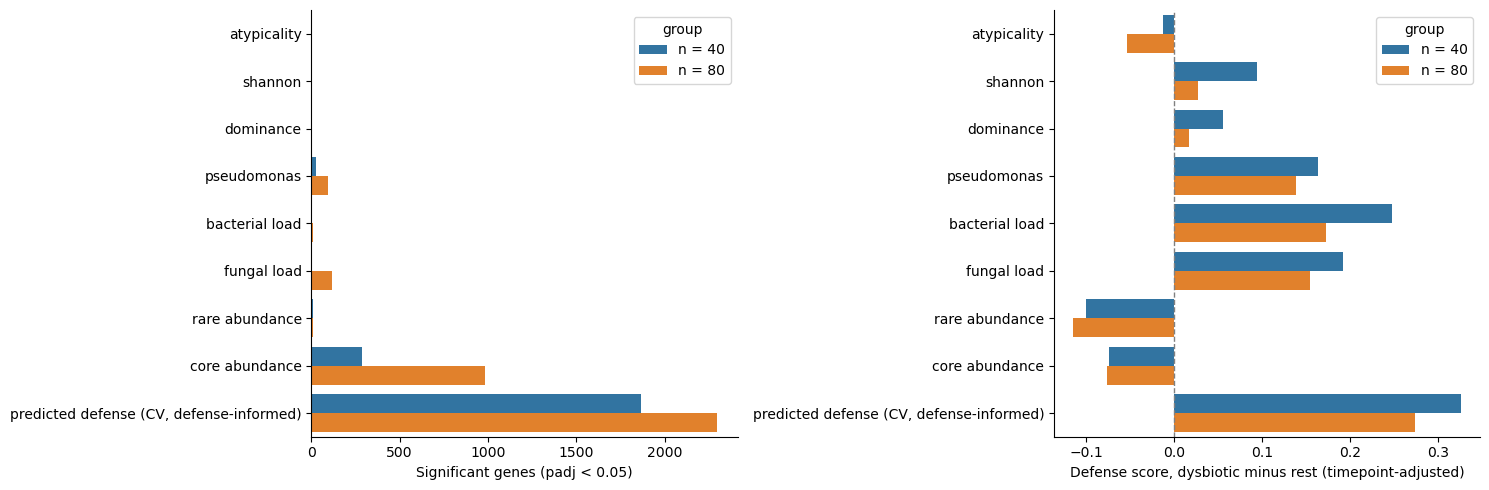

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.patch.set_facecolor("white")
plot_df = alternative_summary.assign(group=lambda df: "n = " + df["group size"].astype(str))
sns.barplot(data=plot_df, y="measure", x="significant (padj < 0.05)", hue="group", ax=axes[0])
axes[0].set_xlabel("Significant genes (padj < 0.05)")
axes[0].set_ylabel("")
sns.barplot(data=plot_df, y="measure", x="defense score diff (timepoint-adjusted)", hue="group", ax=axes[1])
axes[1].axvline(0, color="gray", linestyle="dashed", linewidth=1)
axes[1].set_xlabel("Defense score, dysbiotic minus rest (timepoint-adjusted)")
axes[1].set_ylabel("")
for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()

## Best runs

Top genes for the runs with the most significant genes. GO enrichment of the significant genes (all namespaces) is run for any with at least 10.

In [12]:
import Go_tools

go_term_matrix = pd.read_csv(
    "/Users/michael/Data/Reference_data/Arabdidopsis_go_matrix_from_tair_gaf.csv", index_col=0
)
go_term_names = pd.read_csv("/Users/michael/Data/Reference_data/goterm_names.csv", index_col=0)
background_genes = de_counts.columns.tolist()

best = alternative_summary.sort_values("significant (padj < 0.05)", ascending=False).head(4)
for _, run in best.iterrows():
    results = alternative_results[run["run_id"]]
    significant = results.loc[results["padj"] < 0.05].sort_values("padj")
    print(f"\n=== {run['measure']} (n = {run['group size']}): {len(significant)} significant genes ===")
    if len(significant) == 0:
        continue
    display(
        significant.head(15)[["baseMean", "log2FoldChange", "padj"]]
        .assign(defense_gene=lambda df: df.index.isin(defense_genes))
        .round(4)
    )
    if len(significant) >= 10:
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            tables = Go_tools.generate_contigency_tables(
                go_annotations=go_term_matrix,
                gene_list=significant.index.tolist(),
                use_background_genes=True,
                background_genes=background_genes,
            )
            go_results = Go_tools.multi_hypothesis_correct_fishers_exact(
                Go_tools.fishers_exact_on_contigency_tables(
                    all_go_contigency_tables=tables, original_GO_term_panda=go_term_matrix
                )
            )
        display(
            go_results.merge(go_term_names, left_index=True, right_index=True, how="left")
            .sort_values("P_value")
            .head(10)
        )


=== predicted defense (CV, defense-informed) (n = 80): 2298 significant genes ===


,baseMean,log2FoldChange,padj,defense_gene
AT2G43510,369.1471,0.7561,0.0,False
AT1G52230,3263.5169,-0.3417,0.0,False
AT4G03280,5465.8472,-0.2533,0.0,False
AT1G54500,703.4555,-0.2825,0.0,False
AT4G01150,6025.5504,-0.2829,0.0,False
AT4G37930,2175.5683,-0.2611,0.0,False
AT4G12800,14969.7941,-0.2947,0.0,False
AT2G18660,118.8369,0.8502,0.0,False
AT3G49120,764.6912,0.6388,0.0,True
AT4G20360,8058.1787,-0.2811,0.0,False


,P_value,x
GO:0009535,6.537871e-99,chloroplast thylakoid membrane
GO:0009579,5.161282e-82,thylakoid
GO:0009534,5.585462e-73,chloroplast thylakoid
GO:0009941,8.723338e-63,chloroplast envelope
GO:0009570,1.522188e-60,chloroplast stroma
GO:0009507,2.170121e-57,chloroplast
GO:0048046,1.348305e-30,apoplast
GO:0042742,1.758071e-22,defense response to bacterium
GO:0009543,3.785651e-21,chloroplast thylakoid lumen
GO:0031977,1.127276e-18,thylakoid lumen



=== predicted defense (CV, defense-informed) (n = 40): 1866 significant genes ===


,baseMean,log2FoldChange,padj,defense_gene
AT5G24530,120.2365,1.2118,0.0,False
AT4G12800,14969.7941,-0.4021,0.0,False
AT4G01150,6025.5504,-0.3726,0.0,False
AT2G18660,118.8369,1.1311,0.0,False
AT4G20360,8058.1787,-0.3727,0.0,False
AT1G52230,3263.5169,-0.4264,0.0,False
AT4G32260,2576.2300,-0.3037,0.0,False
AT5G46110,2040.5858,-0.3807,0.0,False
AT4G23170,342.2847,0.8795,0.0,True
AT1G52220,1740.3173,-0.3638,0.0,False


,P_value,x
GO:0009535,2.248816e-99,chloroplast thylakoid membrane
GO:0009579,9.165412e-77,thylakoid
GO:0009534,6.468160e-73,chloroplast thylakoid
GO:0009941,6.233156e-65,chloroplast envelope
GO:0009570,2.520043e-58,chloroplast stroma
GO:0009507,1.199741e-47,chloroplast
GO:0048046,2.918532e-30,apoplast
GO:0042742,1.446739e-18,defense response to bacterium
GO:0050832,9.692367e-17,defense response to fungus
GO:0009543,1.160685e-15,chloroplast thylakoid lumen


... (2 outputs left out)

,P_value,x
GO:0009570,1.909741e-43,chloroplast stroma
GO:0009941,4.713822e-40,chloroplast envelope
GO:0003729,6.531624e-35,mRNA binding
GO:0022626,3.075801e-27,cytosolic ribosome
GO:0009507,1.361151e-25,chloroplast
GO:0009579,1.191025e-24,thylakoid
GO:0006412,4.842327e-21,translation
GO:0009534,4.495442e-20,chloroplast thylakoid
GO:0009535,1.643461e-19,chloroplast thylakoid membrane
GO:0005829,6.831081e-16,cytosol



=== core abundance (n = 40): 285 significant genes ===


,baseMean,log2FoldChange,padj,defense_gene
AT1G23260,171.0913,-0.3085,0.0078,False
AT1G03130,929.0353,0.3329,0.0090,False
AT5G38430,10633.4598,0.3867,0.0090,False
AT5G44430,2600.0428,-2.1330,0.0090,False
AT1G74070,125.9296,0.4283,0.0090,False
AT3G22960,343.9897,0.2671,0.0090,False
AT4G18570,101.6814,0.3704,0.0101,False
AT5G38420,11683.3922,0.4596,0.0101,False
AT4G38580,745.1238,-0.3198,0.0101,False
AT1G60000,599.5190,0.2337,0.0103,False


,P_value,x
GO:0009579,1.424728e-34,thylakoid
GO:0009534,1.813552e-34,chloroplast thylakoid
GO:0009941,1.206617e-33,chloroplast envelope
GO:0009570,1.365652e-32,chloroplast stroma
GO:0009535,1.163886e-29,chloroplast thylakoid membrane
GO:0009507,2.342153e-22,chloroplast
GO:0003729,2.721502e-16,mRNA binding
GO:0048046,4.095087e-10,apoplast
GO:0009543,7.355397e-10,chloroplast thylakoid lumen
GO:0005829,3.302346e-08,cytosol
